# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Pal 2021's malignant manifold is **non-branching**: an scFates PPT *tree* produces only
resolution-dependent forks — the signature of over-triangulating a continuous cloud, not a stable
bifurcation. The three embryonic signatures resolve into a single axis (pSom pole ↔ Crest/Gast
pole; Crest↔pSom spatial r≈−0.9), so we fit one principal **curve** (ElPiGraph) on the joint
embedding — **no re-embedding** of a linear compartment. The display frame `X_umap_lin` is
inherited unchanged from 01 (shared orientation).

In [2]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [3]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells stay on their *original joint embedding coordinates* — no re-embedding. Score the three
embryonic signatures (Gast / pSom / Crest) against the union control pool, then graph-smooth
(knn-connectivity averaging) for reading geography and correlations. Raw per-cell scores are kept
for the deliverable UMAPs in 03.

In [5]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
assert 'X_umap_lin' in adata.obsm, 'shared orientation frame missing'
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 59359 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.35
Gast: 80/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present


### Branching test — honest tree-vs-curve decision
Fit a PPT *tree* at increasing resolution. A genuine bifurcation yields **one stable fork** that
persists; over-triangulation of a continuous cloud yields forks that scale with node count.

In [7]:
def topo(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
forks = {}
for N in [50, 100, 200]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(adata, method='ppt', Nodes=N, ppt_lambda=100, ppt_sigma=0.5,
                    use_rep='X_umap', seed=SEED, plot=False)
    t,f = topo(adata); forks[N] = f
    print(f'PPT tree Nodes={N}: {t} tips, {f} forks')
print('forks scale with resolution ->', forks, '-> non-branching (continuous), fit a curve')

PPT tree Nodes=50: 11 tips, 9 forks
PPT tree Nodes=100: 23 tips, 21 forks
PPT tree Nodes=200: 30 tips, 28 forks
forks scale with resolution -> {50: 9, 100: 21, 200: 28} -> non-branching (continuous), fit a curve


### Fit the principal curve (ElPiGraph) + fold diagnostic
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. The self-approach ratio =
minimum distance between graph-non-adjacent nodes, in units of the median edge length; > 1 means
no fold. We assert 0 forks and a fold-free curve, and render the fitted edges.

In [9]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
sub = adata
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=30, use_rep='X_umap', epg_lambda=0.5, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.52 (>1 = fold-free)


### Derive the root (data-driven, developmental order)
Neural crest is a **late** readout; the root is the curve tip where Gast+pSom is highest and
Crest lowest — the developmental origin. Pseudotime then flows toward the neural-crest terminus.

In [11]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0010 pSom=+0.0145 Crest=-0.0213
tip 2: Gast=-0.0163 pSom=+0.0510 Crest=-0.0419
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.635 p=0.0e+00
  pSom_sm: rho=-0.797 p=0.0e+00
  Crest_sm: rho=+0.729 p=0.0e+00
  cyc_score: rho=-0.569 p=0.0e+00


### Confirm the inherited orientation runs pseudotime left → right
`X_umap_lin` was fixed in 01 (pSom-root at left). Because the root is the pSom-high tip, pseudotime
should increase left→right on that frame; we assert it rather than recomputing (a fresh SVD basis
could silently reflect an axis).

In [13]:
xl = sub.obsm['X_umap_lin']
r = float(np.corrcoef(xl[:,0], sub.obs['t'].values)[0,1])
print(f'corr(x_lin, pseudotime) = {r:+.2f} (inherited frame from 01)')
assert r > 0, 'inherited orientation is not pseudotime left->right'

corr(x_lin, pseudotime) = +0.90 (inherited frame from 01)


### Save manifold + trajectory figure (deliverable) with fitted curve edges

saved manifold.h5ad + manifold.pdf (with fitted curve edges)


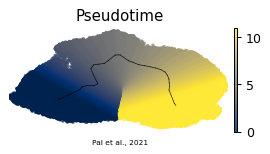

In [15]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
# overlay fitted curve edges on the same X_umap_lin frame (map graph nodes via soft assignment)
Bm = np.asarray(sub.uns['graph']['B']); Rm = np.asarray(sub.obsm['X_R'])
Fnode = (Rm.T @ xl) / Rm.sum(0)[:,None]   # node positions in X_umap_lin coords
ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj):
    ax.plot([Fnode[a,0],Fnode[b,0]],[Fnode[a,1],Fnode[b,1]], '-', c='k', lw=0.6, alpha=.8, zorder=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf (with fitted curve edges)')